<a href="https://colab.research.google.com/github/yabasahilda2004/Bakery_Sales/blob/main/bakery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## IMPORTING LIBRARIES

Libraries used throughout the project: `pandas` and `numpy` for data handling, `matplotlib` and `seaborn` for visualization, and `scikit-learn` for modelling.

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


## DATA LOADING

The bakery dataset (`bakery_sales_dataset.csv`) is loaded into a DataFrame. A first look at its shape, column names, data types and sample rows gives us an overview.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/Bakery_sales/bakery_sales_dataset.csv")

In [ ]:
df.head()

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,...,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
0,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST02,8,6,2,2,25.0,141.48,4
1,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Dry Storage,Low,ST02,4,3,1,1,25.0,39.96,4
2,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST03,3,2,1,1,33.3,103.83,4
3,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Dry Storage,Low,ST03,13,10,3,2,23.1,79.73,4
4,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Room Temperature,Very High,ST03,4,3,1,1,25.0,10.08,4


In [ ]:
df.shape

(19321, 40)

- The dataset has an initial 19321 Rows and 40 Columns

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19321 entries, 0 to 19320
Data columns (total 40 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             19321 non-null  object 
 1   Customer_ID          19321 non-null  object 
 2   Customer_Age         19321 non-null  int64  
 3   Customer_Gender      19321 non-null  object 
 4   Customer_Segment     19321 non-null  object 
 5   Loyalty_Member       19321 non-null  object 
 6   Date                 19321 non-null  object 
 7   Year                 19321 non-null  int64  
 8   Month                19321 non-null  int64  
 9   Day                  19321 non-null  int64  
 10  Day_of_Week          19321 non-null  object 
 11  Weekend              19321 non-null  object 
 12  Hour                 19321 non-null  int64  
 13  Time                 19321 non-null  object 
 14  Season               19321 non-null  object 
 15  Festival             3315 non-null  

In [ ]:
# Checking for missing values in the dataset
df.isna().sum()

,0
Order_ID,0
Customer_ID,0
Customer_Age,0
Customer_Gender,0
Customer_Segment,0
Loyalty_Member,0
Date,0
Year,0
Month,0
Day,0


- Festival columns has 16006 non festival values
- Promotion_Type column has 13826 no promotion values

In [ ]:
# Checking for duplicate rows in the dataset
df.duplicated().sum()

np.int64(0)

## DATA CLEANING AND VALIDATION

In [ ]:
# Filling missing values in 'Festival' and 'Promotion_Type' columns with "None"
df[['Festival', 'Promotion_Type']] = df[['Festival','Promotion_Type']].fillna("None")

- Filled the Blank spaces with "None" to signify there was no festival or promotions at the time

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19321 entries, 0 to 19320
Data columns (total 40 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             19321 non-null  object 
 1   Customer_ID          19321 non-null  object 
 2   Customer_Age         19321 non-null  int64  
 3   Customer_Gender      19321 non-null  object 
 4   Customer_Segment     19321 non-null  object 
 5   Loyalty_Member       19321 non-null  object 
 6   Date                 19321 non-null  object 
 7   Year                 19321 non-null  int64  
 8   Month                19321 non-null  int64  
 9   Day                  19321 non-null  int64  
 10  Day_of_Week          19321 non-null  object 
 11  Weekend              19321 non-null  object 
 12  Hour                 19321 non-null  int64  
 13  Time                 19321 non-null  object 
 14  Season               19321 non-null  object 
 15  Festival             19321 non-null 

In [ ]:
dict = {}
for i in list(df.columns):
    dict[i] = df[i].value_counts().shape[0]
pd.DataFrame(dict,index=["Unique counts"]).transpose()

,Unique counts
Order_ID,6576
Customer_ID,500
Customer_Age,57
Customer_Gender,3
Customer_Segment,4
Loyalty_Member,2
Date,731
Year,2
Month,12
Day,31


- Converting some columns to categorical data type for better memory usage and performance

In [ ]:

cat_cols = ['Customer_Gender','Loyalty_Member','Weekend','Season','Festival', 'Promotion_Type', 'Category','Payment_Method','Promotion_Applied','Storage_Type','Perishability','Customer_Rating']
df[cat_cols] = df[cat_cols].astype('category')

- Converting the 'Date' column to datetime format for easier manipulation and analysis

In [ ]:

df['Date'] = pd.to_datetime(df['Date'], format='mixed')

In [ ]:
df.shape

(19321, 40)

In [ ]:
# Logical checks to look for anomalies in the dataset
checks = {
    'negative quantity':        df['Quantity'] < 0,
    'negative price':           df['Unit_Price'] <= 0,
    'discount outside 0-100':   ~df['Discount_Percentage'].between(0, 100),
    'sold > produced':          df['Units_Sold'] > df['Units_Produced'],
    'cost > unit price':        df['Cost_Price'] > df['Unit_Price'],
    'waste pct outside 0-100':  ~df['Waste_Pct'].between(0, 100),
    'negative stock':           df['Stock_Available'] < 0,
}
for name, mask in checks.items():
    print(f"{name}: {mask.sum()}")

negative quantity: 0
negative price: 0
discount outside 0-100: 0
sold > produced: 0
cost > unit price: 0
waste pct outside 0-100: 0
negative stock: 0


In [ ]:
df.describe()

,Customer_Age,Date,Year,Month,Day,Hour,Temperature,Quantity,Unit_Price,Cost_Price,Discount_Percentage,Selling_Price,Total_Bill,Shelf_Life_Days,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit
count,19321.000000,19321,19321.000000,19321.000000,19321.000000,19321.00000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000
mean,35.541846,2024-01-05 01:21:45.584597248,2023.508100,6.559184,15.871901,12.86481,26.988127,2.226955,87.263624,49.275521,4.345541,83.372033,139.268467,61.117333,4.221469,3.046788,1.174680,1.131101,34.118715,59.196602
min,16.000000,2023-01-01 00:00:00,2023.000000,1.000000,1.000000,7.00000,8.100000,1.000000,7.600000,3.270000,0.000000,5.680000,13.120000,1.000000,2.000000,1.000000,1.000000,1.000000,4.200000,-0.550000
25%,25.000000,2023-07-13 00:00:00,2023.000000,4.000000,8.000000,9.00000,21.200000,1.000000,31.020000,16.900000,0.000000,30.400000,52.120000,3.000000,2.000000,1.000000,1.000000,1.000000,25.000000,20.690000
50%,34.000000,2024-01-06 00:00:00,2024.000000,7.000000,16.000000,12.00000,27.700000,2.000000,45.090000,23.640000,0.000000,42.660000,82.800000,5.000000,3.000000,2.000000,1.000000,1.000000,33.300000,36.760000
75%,45.000000,2024-07-07 00:00:00,2024.000000,10.000000,24.000000,17.00000,33.200000,3.000000,76.650000,52.640000,7.500000,72.030000,146.540000,82.000000,5.000000,4.000000,1.000000,1.000000,50.000000,65.920000
max,73.000000,2024-12-31 00:00:00,2024.000000,12.000000,31.000000,21.00000,44.900000,20.000000,472.420000,296.280000,30.000000,472.420000,1885.960000,729.000000,49.000000,37.000000,16.000000,20.000000,50.000000,767.600000
std,13.733832,NaN,0.499947,3.478048,8.767930,3.94044,8.813511,1.782968,110.481951,65.969024,6.794384,105.762887,157.772593,103.611553,3.635227,3.038092,0.783283,0.752667,12.734206,65.238370


In [ ]:
#Checking the season for which a month falls in
print(pd.crosstab(df['Month'], df['Season']))

Season  Autumn  Monsoon  Summer  Winter
Month                                  
1            0        0       0    1758
2            0        0       0    1379
3            0        0    1660       0
4            0        0    1658       0
5            0        0    1513       0
6            0     1440       0       0
7            0     1507       0       0
8            0     1560       0       0
9            0     1959       0       0
10        1660        0       0       0
11        1587        0       0       0
12           0        0       0    1640


## FEATURE ENGINEERING

New columns were derived from the cleaned data so that the later analysis, forecasting and dashboards can use them directly.

**Date-based features**
- `month_name`, `year_month`: readable labels for monthly trend charts. `year_month` keeps the same month in different years separate.
- `week_number`, `iso_year`: ISO week numbering. `iso_year` is kept alongside it because dates at the start and end of a year can belong to a neighbouring ISO year.

**Indicator features (1 = yes, 0 = no)**
- `is_weekend`: 1 for Saturday and Sunday. 0 for the weekdays.
- `is_festival`: 1 for any of the 9 listed holidays, 0 when the festival value is "None".

**Financial features**
- `Total_Bill`: quantity × unit price, adjusted for any discount.

Renamed `Total_Bill` to `Revenue`

- `profit_margin`: profit divided by revenue, as a percentage.It is used to compare profitability across products, promotions and stores.

In [ ]:
df['month_name'] = df['Date'].dt.month_name()
df['week_number'] = df['Date'].dt.isocalendar().week.astype(int)
df['year_month'] = df['Date'].dt.to_period('M').astype(str)


In [ ]:
df['is_weekend'] = df['Day'].isin([1, 7]).astype(int)

In [ ]:
print(df['Festival'].value_counts(dropna=False))

Festival
None                16006
Ganesh Chaturthi      967
Diwali                438
Dussehra              298
Eid                   290
Independence Day      286
Christmas             283
Republic Day          278
Holi                  244
New Year              231
Name: count, dtype: int64


In [ ]:
df['Festival'] = (df['Festival'] != 'None').astype(int)

In [ ]:
print(df['Festival'].value_counts(dropna=False))

Festival
0    16006
1     3315
Name: count, dtype: int64


In [ ]:
#Renaming Total_Bill to Revenue
df = df.rename(columns={'Total_Bill':'Revenue'})

In [ ]:
print(df['Revenue'].describe())
print((df['Revenue'] < 0).sum())
print(df['Revenue'].isna().sum())

count    19321.000000
mean       139.268467
std        157.772593
min         13.120000
25%         52.120000
50%         82.800000
75%        146.540000
max       1885.960000
Name: Revenue, dtype: float64
0
0


In [ ]:
df['profit_margin'] = df['Profit'] / df['Revenue'] * 100

## APPLICATIONS

1. Exploratory data analysis and sales trend visualization.

In [ ]:
# Summary Statistics
print(df[['Quantity', 'Unit_Price','Selling_Price', 'Revenue', 'Profit', 'profit_margin']].describe())

           Quantity    Unit_Price  Selling_Price       Revenue        Profit  \
count  19321.000000  19321.000000   19321.000000  19321.000000  19321.000000   
mean       2.226955     87.263624      83.372033    139.268467     59.196602   
std        1.782968    110.481951     105.762887    157.772593     65.238370   
min        1.000000      7.600000       5.680000     13.120000     -0.550000   
25%        1.000000     31.020000      30.400000     52.120000     20.690000   
50%        2.000000     45.090000      42.660000     82.800000     36.760000   
75%        3.000000     76.650000      72.030000    146.540000     65.920000   
max       20.000000    472.420000     472.420000   1885.960000    767.600000   

       profit_margin  
count   19321.000000  
mean       43.194202  
std         9.473177  
min        -2.510269  
25%        37.821394  
50%        44.554223  
75%        49.627483  
max        61.984316  


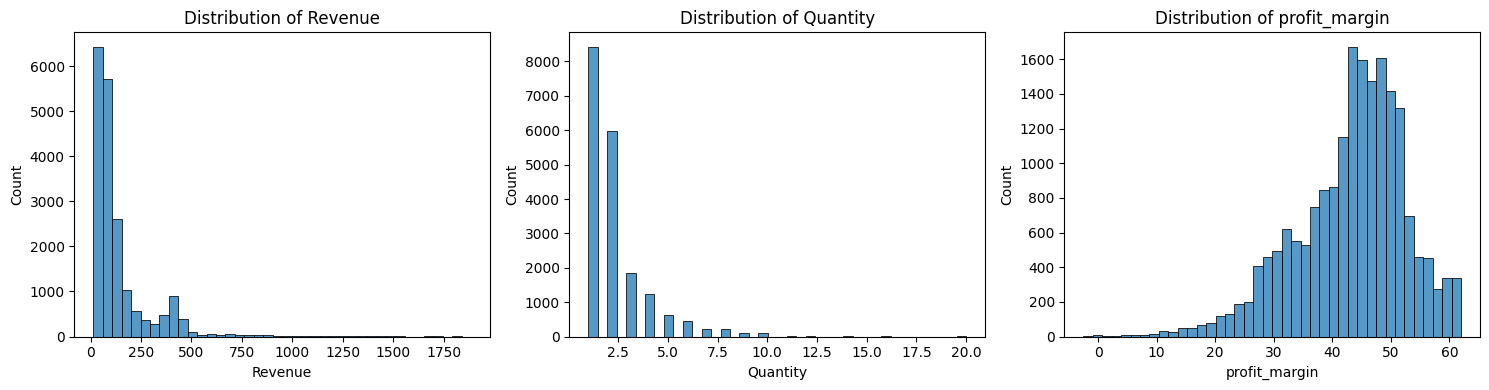

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Revenue', 'Quantity', 'profit_margin']):
    sns.histplot(df[col], bins=40, ax=ax)
    ax.set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

`Revenue` - It is heavily right-skewed. Most sales are small, with the biggest group under 250.

`Quantity` - It is right Skewed .Most sales are 1-3 items.

`profit_margin` - Margins cluster around 40-55%, with a peak near 45-50%, and a tail toward lower values.

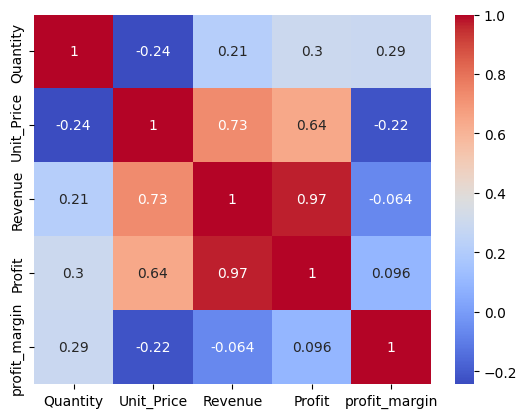

In [ ]:
sns.heatmap(df[['Quantity', 'Unit_Price', 'Revenue', 'Profit', 'profit_margin']].corr(), annot=True, cmap='coolwarm')
plt.show()

**Correlation analysis**

The heatmap shows the linear relationship between the main numeric variables.

- **Revenue and Profit (0.97):** almost perfectly correlated. This is expected, because profit is part of each sale's revenue, so it is not an independent finding.

- **Unit price drives revenue more than quantity does.** `Unit_Price` has a strong positive correlation with `Revenue` (0.73) and `Profit` (0.64), while `Quantity` has only a weak one with `Revenue` (0.21) and `Profit` (0.30). Revenue depends more on which product is sold than on how many items are bought.

- **Quantity and unit price are negatively correlated (-0.24):** customers tend to buy cheaper items in larger numbers.

- **Profit margin is largely independent of revenue (-0.06) and profit (0.10).** A bigger sale does not mean a better margin.

- **Margin has weak relationships with the other two variables:** it rises slightly with quantity (0.29) and falls slightly with unit price (-0.22). Cheaper items bought in larger numbers.



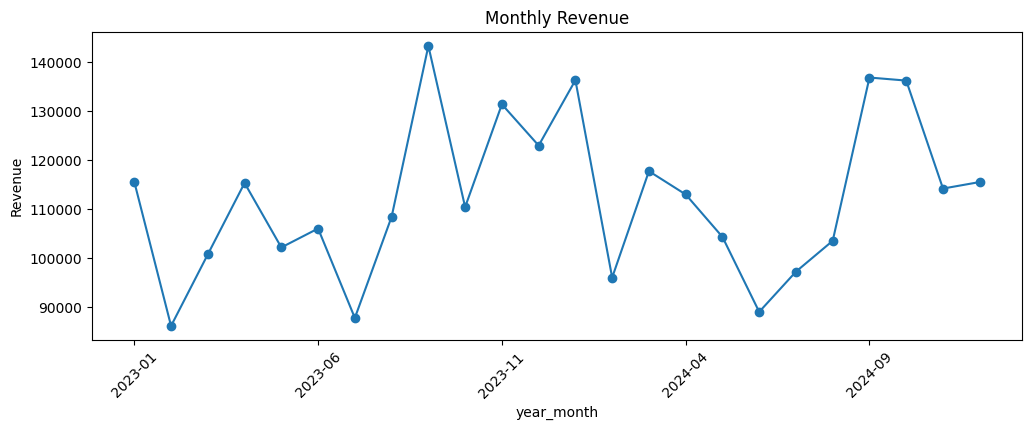

In [ ]:
monthly = df.groupby('year_month')['Revenue'].sum()
monthly.plot(figsize=(12,4), marker= 'o', title = 'Monthly Revenue')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

Monthly revenue fluctuates between roughly 86k and 143k. In both years, revenue is lowest in February and in mid-year (June-July) and peaks in September. Late 2023 stayed high through January 2024, whereas in 2024 revenue fell back after October, so the end-of-year rise is not consistent across both years.